In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv



# Random Forest

## 1. What is Random Forest?

Random Forest is a supervised Machine Learning algorithm based on Ensemble Learning. It combines multiple Decision Trees to produce a more accurate and stable prediction.

Instead of depending on a single Decision Tree, Random Forest builds several trees using different samples of the training dataset and combines their predictions.

It can be used for both:
- Classification: Predicting categorical outcomes.
- Regression: Predicting continuous numerical values.

For classification, the final prediction is generally decided through majority voting.

For regression, the final prediction is calculated by averaging the predictions from all trees.

## 2. Why do we use Random Forest?

A single Decision Tree can easily overfit the training data. It may learn unnecessary patterns and noise, resulting in poor performance on unseen data.

Random Forest addresses this problem by combining multiple Decision Trees.

Each tree is trained using a different bootstrap sample of the original dataset. Additionally, at each split, only a random subset of features is considered.

This introduces diversity among the trees and helps reduce variance.

### Advantages

- Reduces overfitting compared to many individual Decision Trees.
- Generally provides better prediction stability.
- Can handle both classification and regression problems.
- Captures non-linear relationships.
- Provides feature importance scores.
- Works with large datasets containing multiple features.

### Limitations

- Requires more computational resources than a single Decision Tree.
- Takes longer to train when using many trees.
- Less interpretable than an individual Decision Tree.
- Feature importance based on impurity can be biased towards certain features.

## 3. How does Random Forest work?

Random Forest follows these steps:

1. Start with the original training dataset.
2. Generate multiple bootstrap samples by randomly selecting observations with replacement.
3. Train an independent Decision Tree on each bootstrap sample.
4. At every split, consider only a randomly selected subset of features.
5. Allow each tree to grow according to the specified stopping conditions.
6. Collect predictions from all the trees.
7. Combine their predictions to produce the final output.

## 4. Decision Tree vs Random Forest

| Aspect | Decision Tree | Random Forest |
|---|---|---|
| Model | Single tree | Multiple trees |
| Training | Entire training dataset | Bootstrap samples |
| Feature selection | Considers available features | Random subset of features at each split |
| Overfitting | More prone to overfitting | Generally reduces overfitting |
| Variance | Generally high | Generally lower |
| Interpretability | Easy to understand | More difficult |
| Prediction | One tree prediction | Voting or averaging |
| Computational cost | Lower | Higher |

## 5. Bagging vs Random Forest

Both Bagging and Random Forest are Ensemble Learning techniques.

However, they differ in how features are selected during tree construction.

### Bagging

- Creates multiple bootstrap samples.
- Trains independent models on different samples.
- A Decision Tree generally considers all available features when finding the best split.
- Combines predictions using majority voting or averaging.

### Random Forest

- Also uses bootstrap sampling.
- Trains multiple Decision Trees.
- Considers only a random subset of features at each split.
- Combines predictions using majority voting or averaging.

**Key Difference:**

Bagging introduces randomness through bootstrap sampling, whereas Random Forest introduces randomness through both bootstrap sampling and random feature selection.

## 6. Classification vs Regression in Random Forest

| Aspect | Random Forest Classifier | Random Forest Regressor |
|---|---|---|
| Target | Categorical | Continuous |
| Prediction | Class label | Numerical value |
| Combination | Majority voting | Average prediction |
| Example | Predicting survival | Predicting house prices |
| Evaluation | Accuracy, Precision, Recall, F1 | MAE, MSE, RMSE, R² |

## 7. Feature Importance in Random Forest

Random Forest provides feature importance scores to identify which features contribute most to the model's predictions.

One commonly used method is Mean Decrease in Impurity (MDI).

For classification trees, impurity is commonly measured using Gini Impurity.

The importance of a feature is calculated by accumulating the weighted impurity reductions from all splits that use that feature across all trees.

The contributions are then averaged across the forest and normalized.

A higher feature importance score indicates that the feature contributed more to reducing impurity across the forest.

**Important:** Feature importance indicates the model's reliance on a feature. It does not necessarily establish a causal relationship.

## 8. What will we implement in this notebook?

Using the Kaggle Titanic dataset, we will:

1. Explore and understand the dataset.
2. Perform data preprocessing.
3. Build a Decision Tree Classifier.
4. Build a Random Forest Classifier.
5. Evaluate the model using classification metrics.
6. Visualize feature importance.
7. Understand how Random Forest selects important features.
8. Compare Decision Tree and Random Forest performance.

### Final Takeaway

- Decision Tree uses a single tree to make predictions.
- Bagging combines multiple models trained on bootstrap samples.
- Random Forest combines multiple Decision Trees using bootstrap sampling and random feature selection.
- Random Forest generally reduces variance and improves prediction stability.


In [2]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
train = pd.read_csv('/kaggle/input/competitions/titanic/train.csv')

test = pd.read_csv('/kaggle/input/competitions/titanic/test.csv')

gender_submission = pd.read_csv('/kaggle/input/competitions/titanic/gender_submission.csv')

# Display first five rows
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Dataset dimensions
print("Training Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)

# Dataset information
train.info()

Training Dataset Shape: (891, 12)
Testing Dataset Shape: (418, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
# Statistical summary
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Survived
0    549
1    342
Name: count, dtype: int64


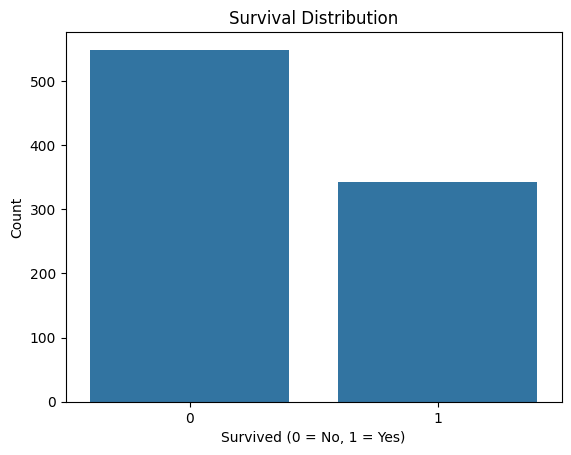

In [5]:
# Check target distribution
print(train['Survived'].value_counts())

sns.countplot(data=train, x='Survived')
plt.title("Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

In [6]:
# Check missing values
missing_values = train.isnull().sum()

# Display columns with missing values
missing_values[missing_values > 0].sort_values(ascending=False)

Cabin       687
Age         177
Embarked      2
dtype: int64

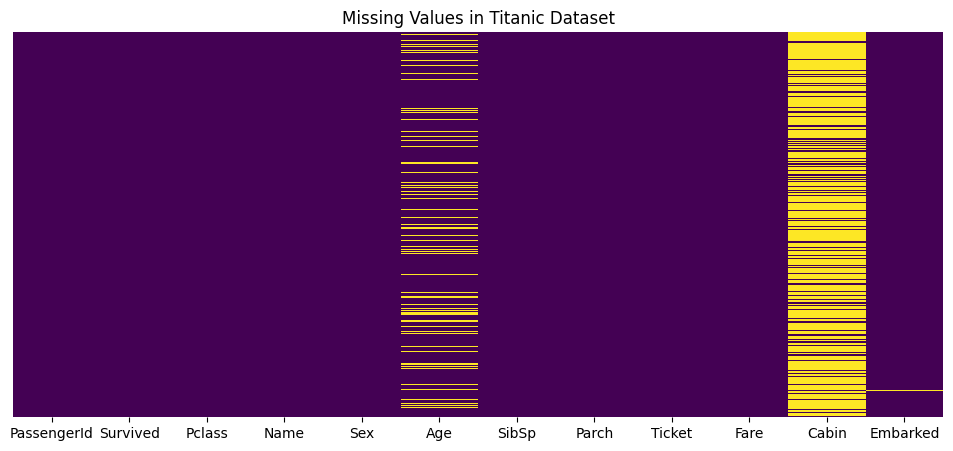

In [7]:
plt.figure(figsize=(12, 5))

sns.heatmap(train.isnull(), cbar=False, yticklabels=False, cmap='viridis')

plt.title("Missing Values in Titanic Dataset")
plt.show()

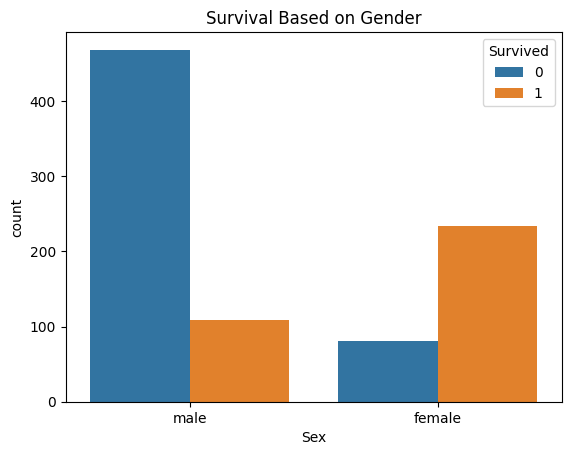

In [8]:
sns.countplot(data=train, x='Sex', hue='Survived')

plt.title("Survival Based on Gender")
plt.show()

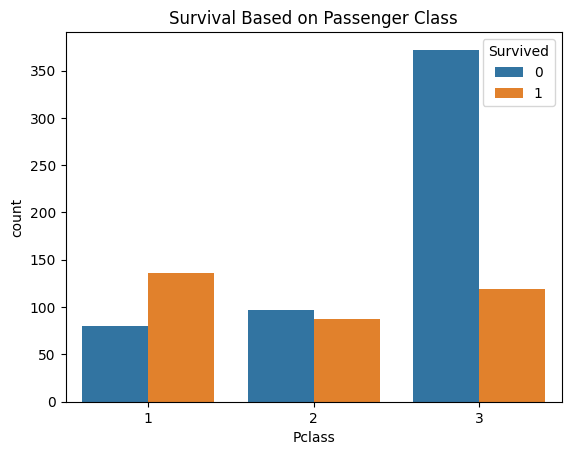

In [9]:
sns.countplot(data=train, x='Pclass', hue='Survived')

plt.title("Survival Based on Passenger Class")
plt.show()

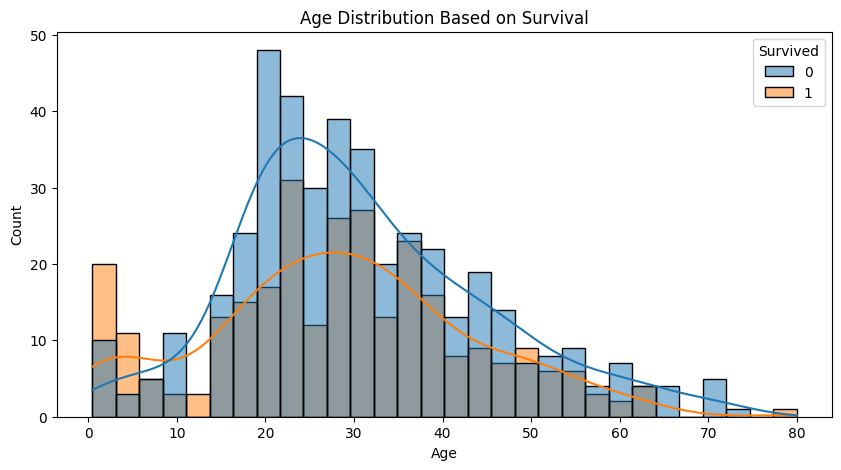

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(data=train, x='Age', hue='Survived', bins=30, kde=True)

plt.title("Age Distribution Based on Survival")
plt.show()

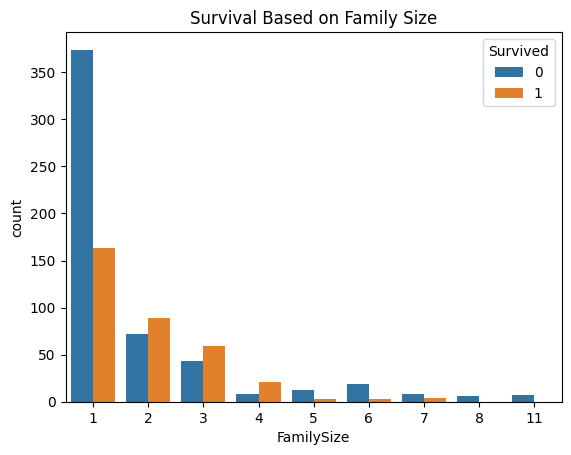

In [11]:
train['FamilySize'] = train['SibSp'] + train['Parch'] + 1

sns.countplot(data=train, x='FamilySize', hue='Survived')

plt.title("Survival Based on Family Size")
plt.show()

In [13]:
# Create FamilySize in training dataset
train['FamilySize'] = train['SibSp'] + train['Parch'] + 1

# Create FamilySize in testing dataset
test['FamilySize'] = test['SibSp'] + test['Parch'] + 1

print("Training FamilySize created:", 'FamilySize' in train.columns)
print("Testing FamilySize created:", 'FamilySize' in test.columns)

Training FamilySize created: True
Testing FamilySize created: True


In [14]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch',
            'Fare', 'Embarked', 'FamilySize']

X = train[features].copy()
y = train['Survived']

X_test = test[features].copy()

X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize
0,3,male,22.0,1,0,7.2500,S,2
1,1,female,38.0,1,0,71.2833,C,2
2,3,female,26.0,0,0,7.9250,S,1
3,1,female,35.0,1,0,53.1000,S,2
4,3,male,35.0,0,0,8.0500,S,1


In [15]:
# Numerical columns
numerical_cols = ['Age', 'Fare']

# Categorical columns
categorical_cols = ['Sex', 'Embarked']

# Fill numerical missing values using training median
for col in numerical_cols:
    median_value = X[col].median()
    X[col] = X[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

# Fill categorical missing values using training mode
for col in categorical_cols:
    mode_value = X[col].mode()[0]
    X[col] = X[col].fillna(mode_value)
    X_test[col] = X_test[col].fillna(mode_value)

print("Training missing values:", X.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())

Training missing values: 0
Testing missing values: 0


In [16]:
# One-hot encoding
X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    drop_first=True
)

# Align testing columns with training columns
X_test = X_test.reindex(columns=X.columns, fill_value=0)

print("Training shape:", X.shape)
print("Testing shape:", X_test.shape)

X.head()

Training shape: (891, 9)
Testing shape: (418, 9)


,Pclass,Age,SibSp,Parch,Fare,FamilySize,Sex_male,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,2,True,False,True
1,1,38.0,1,0,71.2833,2,False,False,False
2,3,26.0,0,0,7.9250,1,False,False,True
3,1,35.0,1,0,53.1000,2,False,False,True
4,3,35.0,0,0,8.0500,1,True,False,True


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (712, 9)
X_val: (179, 9)
y_train: (712,)
y_val: (179,)


In [18]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [19]:
# Predict survival
y_pred = rf_model.predict(X_val)

# Compare actual and predicted values
comparison = pd.DataFrame({
    'Actual Survival': y_val.values,
    'Predicted Survival': y_pred
})

comparison.head(10)

,Actual Survival,Predicted Survival
0,0,0
1,0,0
2,1,0
3,0,0
4,1,1
5,1,0
6,1,1
7,0,1
8,0,1
9,0,0


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred))
print("Recall:", recall_score(y_val, y_pred))
print("F1 Score:", f1_score(y_val, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_val, y_pred))

Accuracy: 0.8100558659217877
Precision: 0.7692307692307693
Recall: 0.7246376811594203
F1 Score: 0.746268656716418

Classification Report:

              precision    recall  f1-score   support

           0       0.83      0.86      0.85       110
           1       0.77      0.72      0.75        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.81      0.81      0.81       179



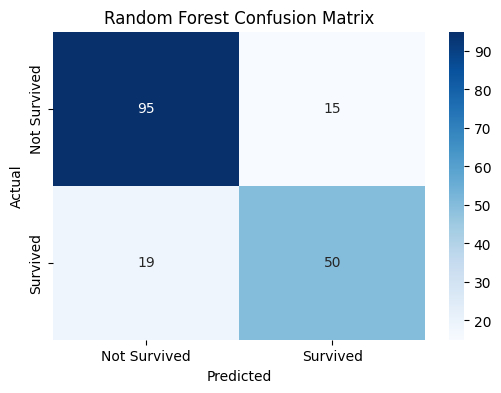

In [21]:
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [22]:
# Extract feature importance
feature_importance = rf_model.feature_importances_

# Create DataFrame
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importance
})

# Sort in descending order
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_df

,Feature,Importance
4,Fare,0.273412
6,Sex_male,0.261490
1,Age,0.237682
0,Pclass,0.085662
5,FamilySize,0.050495
2,SibSp,0.033592
3,Parch,0.024457
8,Embarked_S,0.024002
7,Embarked_Q,0.009208


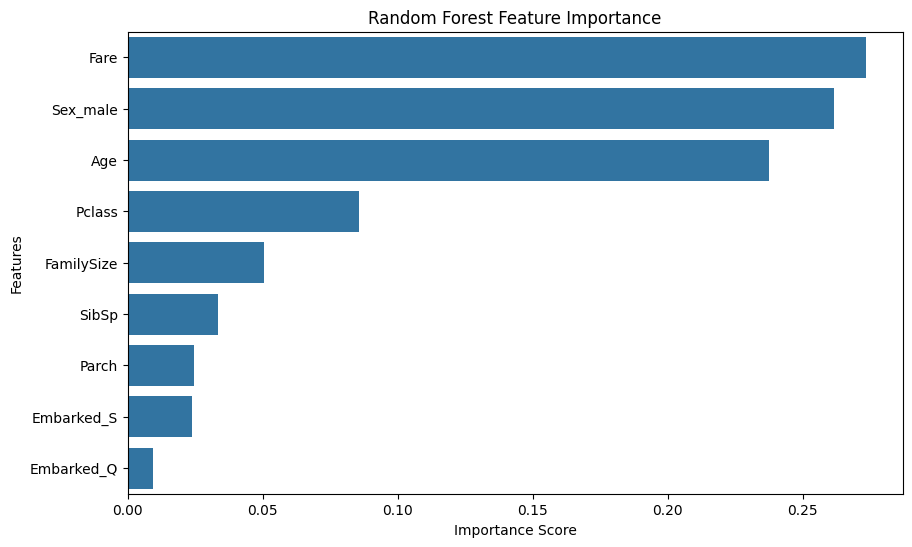

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

In [24]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train model
dt_model.fit(X_train, y_train)

# Predictions
dt_pred = dt_model.predict(X_val)

print("Decision Tree training completed!")

Decision Tree training completed!


In [25]:
# Decision Tree metrics
dt_accuracy = accuracy_score(y_val, dt_pred)
dt_precision = precision_score(y_val, dt_pred)
dt_recall = recall_score(y_val, dt_pred)
dt_f1 = f1_score(y_val, dt_pred)

# Random Forest metrics
rf_accuracy = accuracy_score(y_val, y_pred)
rf_precision = precision_score(y_val, y_pred)
rf_recall = recall_score(y_val, y_pred)
rf_f1 = f1_score(y_val, y_pred)

# Comparison DataFrame
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Accuracy': [dt_accuracy, rf_accuracy],
    'Precision': [dt_precision, rf_precision],
    'Recall': [dt_recall, rf_recall],
    'F1 Score': [dt_f1, rf_f1]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.793296,0.742424,0.710145,0.725926
1,Random Forest,0.810056,0.769231,0.724638,0.746269


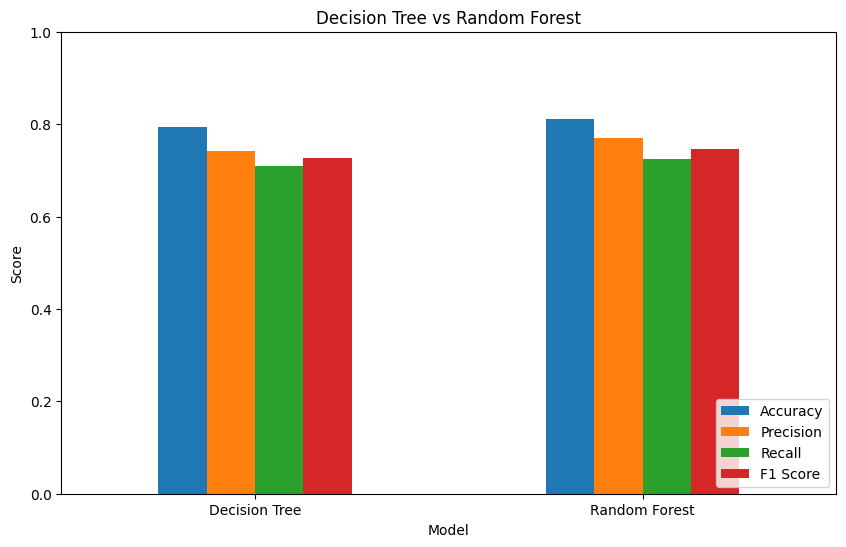

In [26]:
results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6),
    ylim=(0, 1)
)

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [27]:
# Predict survival for Kaggle test dataset
test_predictions = rf_model.predict(X_test)

# Create submission DataFrame
submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived': test_predictions
})

submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,1
4,896,0


In [29]:
submission.to_csv('random_forest_submission.csv', index=False)

print("Submission file created successfully!")

Submission file created successfully!
